In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the data we fetched yesterday
df = pd.read_csv('../data/raw_players.csv')

# Show the first 5 rows to make sure it loaded
df.head()

Matplotlib is building the font cache; this may take a moment.


,id,web_name,element_type,now_cost,transfers_in_event,transfers_out_event,cost_change_event,selected_by_percent,total_points
0,1,Raya,1,62,19638,4559,1,45.5,49
1,2,Arrizabalaga,1,49,29,28,0,0.1,0
2,3,Meslier,1,49,12,15,0,0.0,0
3,4,Gabriel,2,79,31366,5555,0,21.4,52
4,5,J.Timber,2,65,2041,2325,0,0.7,3


In [2]:
# How many players went up in price? Down in price? Stayed the same?
print("Price Increases:", len(df[df['cost_change_event'] > 0]))
print("Price Decreases:", len(df[df['cost_change_event'] < 0]))
print("No Change:", len(df[df['cost_change_event'] == 0]))

Price Increases: 7
Price Decreases: 24
No Change: 638


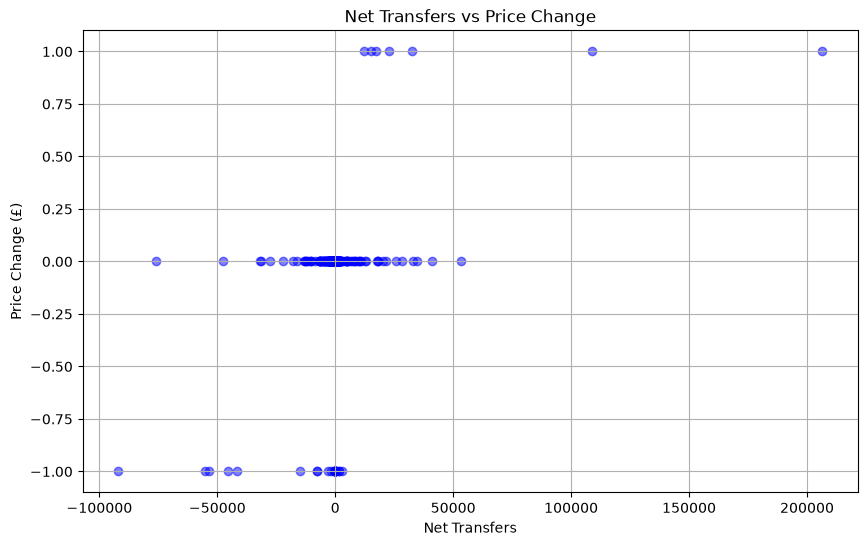

In [3]:
# Calculate Net Transfers (In - Out)
df['net_transfers'] = df['transfers_in_event'] - df['transfers_out_event']

# Plot Net Transfers vs Price Change
plt.figure(figsize=(10, 6))
plt.scatter(df['net_transfers'], df['cost_change_event'], alpha=0.5, color='blue')
plt.title('Net Transfers vs Price Change')
plt.xlabel('Net Transfers')
plt.ylabel('Price Change (£)')
plt.grid(True)
plt.show()

In [5]:
# 1. Calculate the "Velocity" of transfers relative to ownership
# We use selected_by_percent as a proxy for total owners.
df['selected_by_percent'] = df['selected_by_percent'].astype(float)

# Create a new feature: Net transfers per 1% of ownership
# Add a tiny number to selected_by_percent to avoid dividing by zero
df['transfer_velocity'] = df['net_transfers'] / (df['selected_by_percent'] + 0.1)

# 2. Create the Target Variable (What we want to predict)
# Let's simplify the problem: We just want to predict IF the price will rise or fall.
# 1 = Price rose, 0 = Price stayed the same, -1 = Price fell
df['target'] = df['cost_change_event'].apply(lambda x: 1 if x > 0 else (-1 if x < 0 else 0))

# Let's look at a few rows to see our new columns
print(df[['web_name', 'net_transfers', 'selected_by_percent', 'transfer_velocity', 'target']].head())

       web_name  net_transfers  selected_by_percent  transfer_velocity  target
0          Raya          15079                 45.5         330.679825       1
1  Arrizabalaga              1                  0.1           5.000000       0
2       Meslier             -3                  0.0         -30.000000       0
3       Gabriel          25811                 21.4        1200.511628       0
4      J.Timber           -284                  0.7        -355.000000       0


In [4]:
# Convert ownership percentage from string to float
df['selected_by_percent'] = df['selected_by_percent'].astype(float)

# Find the top 5 most bought players
top_bought = df.nlargest(5, 'transfers_in_event')[['web_name', 'transfers_in_event', 'selected_by_percent', 'cost_change_event']]
print("Top 5 Most Bought Players:")
print(top_bought.to_string(index=False))

Top 5 Most Bought Players:
 web_name  transfers_in_event  selected_by_percent  cost_change_event
N.Jackson              208239                  6.1                  1
Tavernier              111088                 14.4                  1
    Konsa               55740                 19.2                  0
   Cherki               50211                 39.1                  0
 Manzambi               42862                  3.4                  0


In [7]:
from sklearn.model_selection import train_test_split

# Select the features we want to use for prediction
# (We are using our new 'transfer_velocity' and the raw net_transfers)
features = ['net_transfers', 'transfer_velocity']
X = df[features]

# Select our target
y = df['target']

# Split the data: 80% for training the model, 20% for testing it
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training data size: {len(X_train)} players")
print(f"Testing data size: {len(X_test)} players")

Training data size: 535 players
Testing data size: 134 players


In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# We will limit the depth of the tree so it can't just memorize the data
model = RandomForestClassifier(n_estimators=100, max_depth=4, random_state=42)

# Train the model
model.fit(X_train, y_train)

# Make predictions
predictions = model.predict(X_test)

# Let's look at a much more detailed report than just "accuracy"
print("Classification Report:")
print(classification_report(y_test, predictions))

Classification Report:
              precision    recall  f1-score   support

          -1       0.00      0.00      0.00         4
           0       0.95      0.99      0.97       127
           1       0.00      0.00      0.00         3

    accuracy                           0.94       134
   macro avg       0.32      0.33      0.32       134
weighted avg       0.90      0.94      0.92       134



c:\Users\vaibh\Downloads\fpl-price-change-predictor\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\vaibh\Downloads\fpl-price-change-predictor\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\vaibh\Downloads\fpl-price-change-predictor\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p

In [10]:
import pandas as pd

# See which feature the model thought was most important
importances = pd.Series(model.feature_importances_, index=X.columns)
print("Feature Importance:")
print(importances)

Feature Importance:
net_transfers        0.521517
transfer_velocity    0.478483
dtype: float64
